In [1]:
import os, time, math, copy, random, json
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
import pandas as pd

QUICK = False          # True -> tiny subset + few epochs, just to check that everything runs

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'
print('device:', device, '| torch', torch.__version__, '| AMP:', USE_AMP)
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))

def seed_all(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_all(0)
torch.backends.cudnn.benchmark = True

# ---- experiment sizes (full vs quick) --------------------------------------
CFG = dict(
    n_train   = 45_000 if not QUICK else 2_000,
    n_val     = 5_000  if not QUICK else 1_000,
    ep_t1     = 10 if not QUICK else 1,     # Task 1c MLP epochs
    ep_t2     = 8  if not QUICK else 1,     # Task 2c epochs per (optimizer, lr)
    ep_t3a    = 30 if not QUICK else 1,     # Task 3a epochs (5k subset)
    n_t3a     = 5_000 if not QUICK else 1_000,
    ep_t3b    = 20 if not QUICK else 1,     # Task 3b epochs per network
    depths_3b = [8, 20, 56] if not QUICK else [8, 20],
    ep_t4     = 20 if not QUICK else 1,     # Task 4 (hard limit 20)
    bs        = 128,
)
print(json.dumps(CFG, indent=1))

device: cuda | torch 2.11.0+cu130 | AMP: True
Tesla T4
{
 "n_train": 45000,
 "n_val": 5000,
 "ep_t1": 10,
 "ep_t2": 8,
 "ep_t3a": 30,
 "n_t3a": 5000,
 "ep_t3b": 20,
 "depths_3b": [
  8,
  20,
  56
 ],
 "ep_t4": 20,
 "bs": 128
}


100%|██████████| 170M/170M [46:18<00:00, 61.4kB/s]


train (45000, 3, 32, 32) val (5000, 3, 32, 32)
channel mean [0.4912 0.482  0.4464] std [0.2472 0.2436 0.2617]


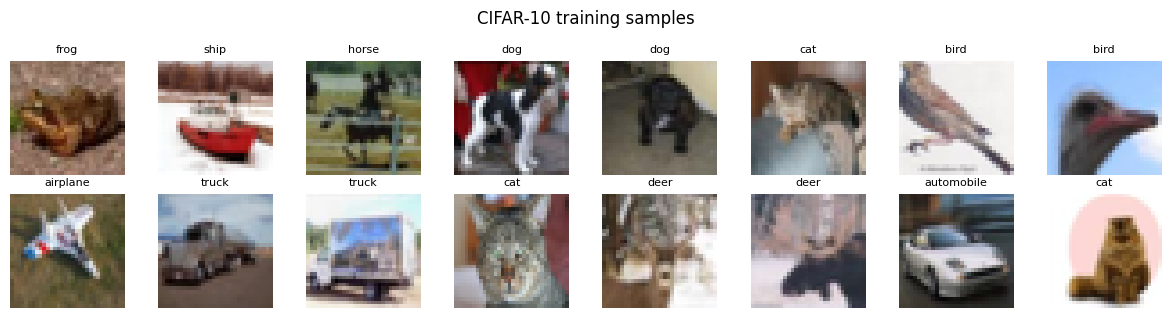

In [2]:
root = './data'
full_train = torchvision.datasets.CIFAR10(root, train=True, download=True)
X_all = torch.from_numpy(np.asarray(full_train.data)).permute(0, 3, 1, 2).contiguous()   # (50000,3,32,32) uint8
y_all = torch.tensor(full_train.targets, dtype=torch.long)
CLASSES = full_train.classes

# fixed, seeded 45k / 5k split
g = torch.Generator().manual_seed(0)
perm = torch.randperm(len(X_all), generator=g)
tr_idx, va_idx = perm[:45_000], perm[45_000:50_000]
tr_idx, va_idx = tr_idx[:CFG['n_train']], va_idx[:CFG['n_val']]

X_tr, y_tr = X_all[tr_idx], y_all[tr_idx]
X_va, y_va = X_all[va_idx], y_all[va_idx]

# per-channel mean / std from the TRAINING split only
MEAN = X_tr.float().div(255).mean(dim=(0, 2, 3))
STD  = X_tr.float().div(255).std(dim=(0, 2, 3))
print('train', tuple(X_tr.shape), 'val', tuple(X_va.shape))
print('channel mean', MEAN.numpy().round(4), 'std', STD.numpy().round(4))

X_tr, y_tr, X_va, y_va = X_tr.to(device), y_tr.to(device), X_va.to(device), y_va.to(device)
MEAN_D, STD_D = MEAN.to(device).view(1, 3, 1, 1), STD.to(device).view(1, 3, 1, 1)

def normalize(x_uint8):
    return (x_uint8.float().div_(255) - MEAN_D) / STD_D

class GPULoader:
    '''Iterates over (x, y) mini-batches that already live on the GPU.
    aug: optional function applied to the normalised float batch.'''
    def __init__(self, X, y, bs, shuffle=True, aug=None, drop_last=False):
        self.X, self.y, self.bs, self.shuffle, self.aug, self.drop_last = X, y, bs, shuffle, aug, drop_last
    def __len__(self):
        n = len(self.X)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)
    def __iter__(self):
        n = len(self.X)
        idx = torch.randperm(n, device=self.X.device) if self.shuffle else torch.arange(n, device=self.X.device)
        for i in range(0, n - (n % self.bs if self.drop_last else 0), self.bs):
            b = idx[i:i + self.bs]
            x = normalize(self.X[b])
            if self.aug is not None:
                x = self.aug(x)
            yield x, self.y[b]

# a quick look at the data
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_tr[i].permute(1, 2, 0).cpu().numpy()); ax.set_title(CLASSES[y_tr[i]], fontsize=8); ax.axis('off')
plt.suptitle('CIFAR-10 training samples'); plt.tight_layout(); plt.show()

In [4]:
class Linear:
    def __init__(self, in_features, out_features):
        self.W = torch.randn(in_features, out_features, device=device) * (2 / in_features) ** 0.5
        self.b = torch.zeros(out_features, device=device)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, grad):
        self.dW = self.x.T @ grad
        self.db = grad.sum(dim=0)
        return grad @ self.W.T


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x.clamp(min=0)

    def backward(self, grad):
        return grad * self.mask


def softmax_cross_entropy(logits, targets):
    # Numerically stable softmax
    shifted = logits - logits.max(dim=1, keepdim=True).values
    exp_scores = shifted.exp()
    probs = exp_scores / exp_scores.sum(dim=1, keepdim=True)

    n = logits.shape[0]
    loss = -torch.log(
        probs[torch.arange(n, device=device), targets] + 1e-12
    ).mean()

    grad = probs.clone()
    grad[torch.arange(n, device=device), targets] -= 1
    grad /= n

    return loss, grad

In [5]:
class MLP:
    def __init__(self, input_size=3072, hidden_size=256, num_classes=10):
        self.fc1 = Linear(input_size, hidden_size)
        self.relu = ReLU()
        self.fc2 = Linear(hidden_size, num_classes)

    def forward(self, x):
        x = x.flatten(start_dim=1)
        x = self.fc1.forward(x)
        x = self.relu.forward(x)
        return self.fc2.forward(x)

    def backward(self, grad):
        grad = self.fc2.backward(grad)
        grad = self.relu.backward(grad)
        self.fc1.backward(grad)

    def parameters(self):
        return [
            (self.fc1.W, self.fc1.dW),
            (self.fc1.b, self.fc1.db),
            (self.fc2.W, self.fc2.dW),
            (self.fc2.b, self.fc2.db),
        ]

In [6]:
model = MLP().to(device) if False else MLP()

x, y = next(iter(GPULoader(X_tr, y_tr, bs=64, shuffle=True)))

logits = model.forward(x)
loss, grad = softmax_cross_entropy(logits, y)
model.backward(grad)

print("Logits shape:", logits.shape)
print("Loss:", loss.item())
print("Weight gradient shape:", model.fc1.dW.shape)

Logits shape: torch.Size([64, 10])
Loss: 3.459329605102539
Weight gradient shape: torch.Size([3072, 256])


In [7]:
import torch.nn.functional as F

# Use a small batch for verification
x_test, y_test = x[:8], y[:8]

# 1. Manual gradients
logits = model.forward(x_test)
loss_manual, grad = softmax_cross_entropy(logits, y_test)
model.backward(grad)

manual_grads = [
    model.fc1.dW.clone(), model.fc1.db.clone(),
    model.fc2.dW.clone(), model.fc2.db.clone()
]

# 2. Autograd reference
W1 = model.fc1.W.detach().clone().requires_grad_(True)
b1 = model.fc1.b.detach().clone().requires_grad_(True)
W2 = model.fc2.W.detach().clone().requires_grad_(True)
b2 = model.fc2.b.detach().clone().requires_grad_(True)

z1 = x_test.flatten(1) @ W1 + b1
h1 = z1.relu()
logits_ref = h1 @ W2 + b2
loss_ref = F.cross_entropy(logits_ref, y_test)
loss_ref.backward()

auto_grads = [W1.grad, b1.grad, W2.grad, b2.grad]

# Relative errors and allclose checks
for name, gm, ga in zip(
    ["W1", "b1", "W2", "b2"], manual_grads, auto_grads
):
    rel_error = (gm - ga).norm() / (ga.norm() + 1e-12)
    print(name, "relative error:", rel_error.item(),
          "| allclose:", torch.allclose(gm, ga, rtol=1e-4, atol=1e-6))

W1 relative error: 6.202941449373611e-08 | allclose: True
b1 relative error: 6.82342431446159e-08 | allclose: True
W2 relative error: 3.837935480532906e-08 | allclose: True
b2 relative error: 2.620320316282232e-08 | allclose: True


In [17]:
def loss_at(W1, b1, W2, b2):
    logits = (x_test.flatten(1) @ W1 + b1).relu() @ W2 + b2
    return F.cross_entropy(logits, y_test)

eps = 1e-3

checks = [
    (model.fc1.W, model.fc1.dW, (0, 0)),
    (model.fc1.b, model.fc1.db, (0,)),
    (model.fc2.W, model.fc2.dW, (0, 0)),
    (model.fc2.b, model.fc2.db, (0,))
]

for i, (param, grad_manual, idx) in enumerate(checks):
    original = param[idx].item()

    with torch.no_grad():
        param[idx] = original + eps
    plus = loss_at(model.fc1.W, model.fc1.b,
                   model.fc2.W, model.fc2.b).item()

    with torch.no_grad():
        param[idx] = original - eps
    minus = loss_at(model.fc1.W, model.fc1.b,
                    model.fc2.W, model.fc2.b).item()

    with torch.no_grad():
        param[idx] = original

    numerical = (plus - minus) / (2 * eps)
    analytical = grad_manual[idx].item()
    rel_error = abs(numerical - analytical) / (
        abs(numerical) + abs(analytical) + 1e-12
    )

    print(f"Parameter {i}: manual={analytical:.6g}, "
          f"finite difference={numerical:.6g}, "
          f"relative error={rel_error:.3e}")

Parameter 0: manual=0.00655339, finite difference=0.0149906, relative error=3.916e-01
Parameter 1: manual=-0.0103872, finite difference=0.0130534, relative error=1.000e+00
Parameter 2: manual=-0.0279358, finite difference=0.0351965, relative error=1.000e+00
Parameter 3: manual=-0.0151209, finite difference=0.0171363, relative error=1.000e+00


In [20]:
EPOCHS = 50
BATCH_SIZE = 256
LR = 0.01
# Start a completely fresh experiment
torch.manual_seed(42)
model = MLP()

# Reset experiment history too
history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": []
}

for epoch in range(EPOCHS):
    total_loss, correct, total = 0.0, 0, 0

    for xb, yb in GPULoader(X_tr, y_tr, BATCH_SIZE, shuffle=True):
        logits = model.forward(xb)
        loss, grad = softmax_cross_entropy(logits, yb)
        model.backward(grad)

        with torch.no_grad():
            for param, g in model.parameters():
                param -= LR * g

        total_loss += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        total += len(yb)

    history["train_loss"].append(total_loss / total)
    history["train_acc"].append(100 * correct / total)

    # Validation: no weight updates
    val_loss_sum, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for xb, yb in GPULoader(X_va, y_va, BATCH_SIZE, shuffle=False):
            logits = model.forward(xb)
            loss, _ = softmax_cross_entropy(logits, yb)

            val_loss_sum += loss.item() * len(yb)
            val_correct += (logits.argmax(1) == yb).sum().item()
            val_total += len(yb)

    history["val_loss"].append(val_loss_sum / val_total)
    history["val_acc"].append(100 * val_correct / val_total)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Train loss: {history['train_loss'][-1]:.4f} | "
        f"Val loss: {history['val_loss'][-1]:.4f} | "
        f"Train acc: {history['train_acc'][-1]:.2f}% | "
        f"Val acc: {history['val_acc'][-1]:.2f}%"
    )

Epoch 01/50 | Train loss: 1.9151 | Val loss: 1.7731 | Train acc: 33.22% | Val acc: 37.82%
Epoch 02/50 | Train loss: 1.6675 | Val loss: 1.6952 | Train acc: 41.66% | Val acc: 40.16%
Epoch 03/50 | Train loss: 1.5819 | Val loss: 1.6459 | Train acc: 44.81% | Val acc: 42.50%
Epoch 04/50 | Train loss: 1.5256 | Val loss: 1.6093 | Train acc: 46.99% | Val acc: 43.22%
Epoch 05/50 | Train loss: 1.4831 | Val loss: 1.5897 | Train acc: 48.40% | Val acc: 44.22%
Epoch 06/50 | Train loss: 1.4465 | Val loss: 1.5682 | Train acc: 50.02% | Val acc: 45.10%
Epoch 07/50 | Train loss: 1.4158 | Val loss: 1.5563 | Train acc: 51.28% | Val acc: 45.44%
Epoch 08/50 | Train loss: 1.3875 | Val loss: 1.5417 | Train acc: 52.20% | Val acc: 46.34%
Epoch 09/50 | Train loss: 1.3634 | Val loss: 1.5284 | Train acc: 53.05% | Val acc: 46.46%
Epoch 10/50 | Train loss: 1.3400 | Val loss: 1.5164 | Train acc: 53.96% | Val acc: 47.78%
Epoch 11/50 | Train loss: 1.3193 | Val loss: 1.5078 | Train acc: 54.84% | Val acc: 47.90%
Epoch 12/5

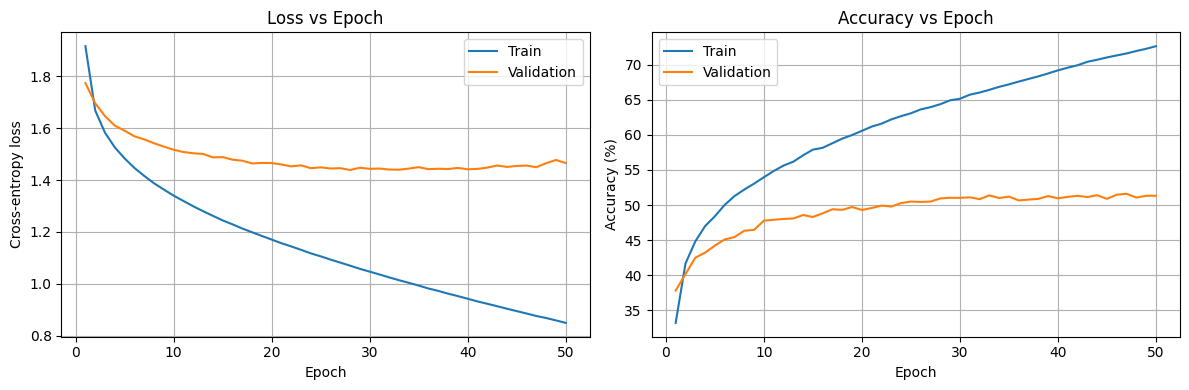

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, EPOCHS + 1)

axes[0].plot(epochs, history["train_loss"], label="Train")
axes[0].plot(epochs, history["val_loss"], label="Validation")
axes[0].set_title("Loss vs Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, history["train_acc"], label="Train")
axes[1].plot(epochs, history["val_acc"], label="Validation")
axes[1].set_title("Accuracy vs Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [15]:
correct, total = 0, 0

with torch.no_grad():
    for xb, yb in GPULoader(X_va, y_va, BATCH_SIZE, shuffle=False):
        logits = model.forward(xb)
        predictions = logits.argmax(dim=1)
        correct += (predictions == yb).sum().item()
        total += len(yb)

val_accuracy = 100 * correct / total
print(f"Validation accuracy: {val_accuracy:.2f}%")

Validation accuracy: 49.92%


In [16]:
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)

# 10 linear layers: input -> 9 hidden layers -> 10 classes
sizes = [3072] + [128] * 9 + [10]

# Shared Xavier initialization for a controlled comparison
initial_weights, initial_biases = [], []

for fan_in, fan_out in zip(sizes[:-1], sizes[1:]):
    w = torch.empty(fan_in, fan_out, device=device)
    nn.init.xavier_uniform_(w)
    initial_weights.append(w)
    initial_biases.append(torch.zeros(fan_out, device=device))


def gradient_norms(activation):
    weights = [
        w.detach().clone().requires_grad_(True)
        for w in initial_weights
    ]
    biases = [
        b.detach().clone().requires_grad_(True)
        for b in initial_biases
    ]

    x, y = next(iter(GPULoader(X_tr, y_tr, bs=128, shuffle=False)))
    x = x.flatten(1)

    for i, (w, b) in enumerate(zip(weights, biases)):
        x = x @ w + b
        if i < len(weights) - 1:
            x = activation(x)

    loss = F.cross_entropy(x, y)
    loss.backward()

    return [w.grad.norm().item() for w in weights]


sigmoid_norms = gradient_norms(torch.sigmoid)
relu_norms = gradient_norms(F.relu)

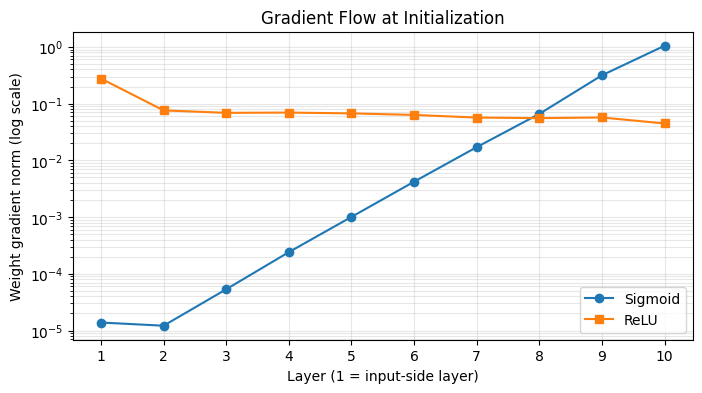

In [19]:
layers = range(1, 11)

plt.figure(figsize=(8, 4))
plt.semilogy(layers, sigmoid_norms, marker='o', label='Sigmoid')
plt.semilogy(layers, relu_norms, marker='s', label='ReLU')
plt.xlabel("Layer (1 = input-side layer)")
plt.ylabel("Weight gradient norm (log scale)")
plt.title("Gradient Flow at Initialization")
plt.xticks(list(layers))
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

#2

In [22]:
class SGDMomentum(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.9):
        super().__init__(params, dict(lr=lr, momentum=momentum))

    @torch.no_grad()
    def step(self, closure=None):
        loss = closure() if closure is not None else None

        for group in self.param_groups:
            lr, momentum = group["lr"], group["momentum"]

            for p in group["params"]:
                if p.grad is None:
                    continue

                g = p.grad
                state = self.state[p]

                if "buffer" not in state:
                    state["buffer"] = g.clone()
                else:
                    state["buffer"].mul_(momentum).add_(g)

                p.add_(state["buffer"], alpha=-lr)

        return loss


class ManualAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=0.001, betas=(0.9, 0.999), eps=1e-8):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps))

    @torch.no_grad()
    def step(self, closure=None):
        loss = closure() if closure is not None else None

        for group in self.param_groups:
            lr = group["lr"]
            beta1, beta2 = group["betas"]
            eps = group["eps"]

            for p in group["params"]:
                if p.grad is None:
                    continue

                g = p.grad
                state = self.state[p]

                if not state:
                    state["step"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)

                state["step"] += 1
                t = state["step"]
                m, v = state["m"], state["v"]

                m.mul_(beta1).add_(g, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(g, g, value=1 - beta2)

                m_hat = m / (1 - beta1**t)
                v_hat = v / (1 - beta2**t)

                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)

        return loss

In [23]:
def check_optimizer(custom_cls, builtin_cls, kwargs):
    p1 = torch.nn.Parameter(torch.tensor([1.0, -2.0, 3.0], device=device))
    p2 = torch.nn.Parameter(p1.detach().clone())

    opt1 = custom_cls([p1], **kwargs)
    opt2 = builtin_cls([p2], **kwargs)

    for grad in [
        [0.2, -0.5, 0.1],
        [-0.1, 0.3, 0.7],
        [0.4, 0.2, -0.2],
    ]:
        g = torch.tensor(grad, device=device)
        p1.grad = g.clone()
        p2.grad = g.clone()

        opt1.step()
        opt2.step()

    print("Custom parameters:", p1.detach())
    print("PyTorch parameters:", p2.detach())
    print("Match:", torch.allclose(p1, p2, rtol=1e-5, atol=1e-7))


check_optimizer(
    SGDMomentum, torch.optim.SGD,
    {"lr": 0.01, "momentum": 0.9}
)

check_optimizer(
    ManualAdam, torch.optim.Adam,
    {"lr": 0.001, "betas": (0.9, 0.999), "eps": 1e-8}
)

Custom parameters: tensor([ 0.9925, -1.9942,  2.9860], device='cuda:0')
PyTorch parameters: tensor([ 0.9925, -1.9942,  2.9860], device='cuda:0')
Match: True
Custom parameters: tensor([ 0.9981, -1.9989,  2.9977], device='cuda:0')
PyTorch parameters: tensor([ 0.9981, -1.9989,  2.9977], device='cuda:0')
Match: True


In [24]:
def run_trajectory(optimizer_name, lr, steps=100):
    xy = torch.nn.Parameter(torch.tensor([2.0, 1.0], device=device))

    if optimizer_name == "SGD":
        opt = torch.optim.SGD([xy], lr=lr)
    elif optimizer_name == "Momentum":
        opt = torch.optim.SGD([xy], lr=lr, momentum=0.9)
    else:
        opt = torch.optim.Adam([xy], lr=lr)

    path = [xy.detach().cpu().numpy().copy()]

    for _ in range(steps):
        opt.zero_grad()
        loss = 0.5 * (xy[0]**2 + 50 * xy[1]**2)
        loss.backward()
        opt.step()
        path.append(xy.detach().cpu().numpy().copy())

    return np.array(path)


paths = {
    "SGD": run_trajectory("SGD", lr=0.02),
    "Momentum": run_trajectory("Momentum", lr=0.002),
    "Adam": run_trajectory("Adam", lr=0.1),
}

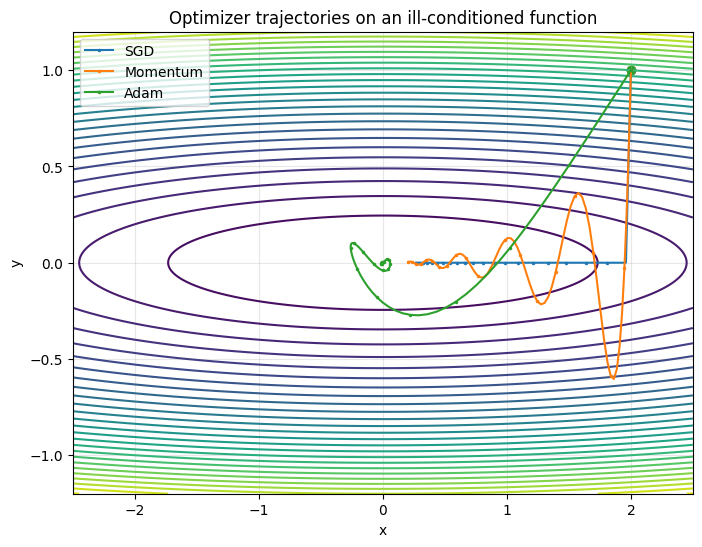

In [25]:
xg = np.linspace(-2.5, 2.5, 250)
yg = np.linspace(-1.2, 1.2, 250)
XX, YY = np.meshgrid(xg, yg)
ZZ = 0.5 * (XX**2 + 50 * YY**2)

plt.figure(figsize=(8, 6))
plt.contour(XX, YY, ZZ, levels=30)

for name, path in paths.items():
    plt.plot(path[:, 0], path[:, 1], marker=".", markersize=3,
             markevery=5, label=name)
    plt.scatter(path[0, 0], path[0, 1], s=35)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Optimizer trajectories on an ill-conditioned function")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [26]:
import torch.nn as nn

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )
        self.classifier = nn.Linear(128, 10)

    def forward(self, x):
        return self.classifier(self.features(x))

In [27]:
def train_experiment(optimizer_name, lr, epochs=8):
    torch.manual_seed(42)
    net = SmallCNN().to(device)

    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(net.parameters(), lr=lr)
    elif optimizer_name == "Momentum":
        optimizer = torch.optim.SGD(net.parameters(), lr=lr, momentum=0.9)
    else:
        optimizer = torch.optim.Adam(net.parameters(), lr=lr)

    results = {"train_loss": [], "val_acc": []}

    for epoch in range(epochs):
        net.train()
        loss_sum, n = 0.0, 0

        for xb, yb in GPULoader(X_tr, y_tr, 256, shuffle=True):
            optimizer.zero_grad()
            logits = net(xb)
            loss = F.cross_entropy(logits, yb)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * len(yb)
            n += len(yb)

        results["train_loss"].append(loss_sum / n)

        net.eval()
        correct, total = 0, 0

        with torch.no_grad():
            for xb, yb in GPULoader(X_va, y_va, 256, shuffle=False):
                pred = net(xb).argmax(1)
                correct += (pred == yb).sum().item()
                total += len(yb)

        results["val_acc"].append(100 * correct / total)

        print(
            f"{optimizer_name} lr={lr:g} "
            f"epoch={epoch+1}/{epochs} "
            f"loss={results['train_loss'][-1]:.4f} "
            f"val_acc={results['val_acc'][-1]:.2f}%"
        )

    return results

In [28]:
LR_CONFIG = {
    "SGD":      [0.01, 0.05, 0.1],
    "Momentum": [0.01, 0.05, 0.1],
    "Adam":     [0.0003, 0.001, 0.003]
}

experiments = {}

for optimizer_name, rates in LR_CONFIG.items():
    for lr in rates:
        key = (optimizer_name, lr)
        experiments[key] = train_experiment(
            optimizer_name, lr, epochs=8
        )

SGD lr=0.01 epoch=1/8 loss=2.0715 val_acc=32.38%
SGD lr=0.01 epoch=2/8 loss=1.8569 val_acc=37.22%
SGD lr=0.01 epoch=3/8 loss=1.7403 val_acc=39.60%
SGD lr=0.01 epoch=4/8 loss=1.6654 val_acc=39.98%
SGD lr=0.01 epoch=5/8 loss=1.6130 val_acc=43.30%
SGD lr=0.01 epoch=6/8 loss=1.5611 val_acc=45.36%
SGD lr=0.01 epoch=7/8 loss=1.5137 val_acc=47.56%
SGD lr=0.01 epoch=8/8 loss=1.4721 val_acc=48.44%
SGD lr=0.05 epoch=1/8 loss=1.8163 val_acc=41.96%
SGD lr=0.05 epoch=2/8 loss=1.5388 val_acc=46.32%
SGD lr=0.05 epoch=3/8 loss=1.3982 val_acc=50.44%
SGD lr=0.05 epoch=4/8 loss=1.3113 val_acc=46.48%
SGD lr=0.05 epoch=5/8 loss=1.2451 val_acc=53.94%
SGD lr=0.05 epoch=6/8 loss=1.1905 val_acc=51.66%
SGD lr=0.05 epoch=7/8 loss=1.1488 val_acc=55.48%
SGD lr=0.05 epoch=8/8 loss=1.1128 val_acc=55.58%
SGD lr=0.1 epoch=1/8 loss=1.7136 val_acc=44.88%
SGD lr=0.1 epoch=2/8 loss=1.4215 val_acc=45.52%
SGD lr=0.1 epoch=3/8 loss=1.2910 val_acc=50.62%
SGD lr=0.1 epoch=4/8 loss=1.2115 val_acc=52.36%
SGD lr=0.1 epoch=5/8 los

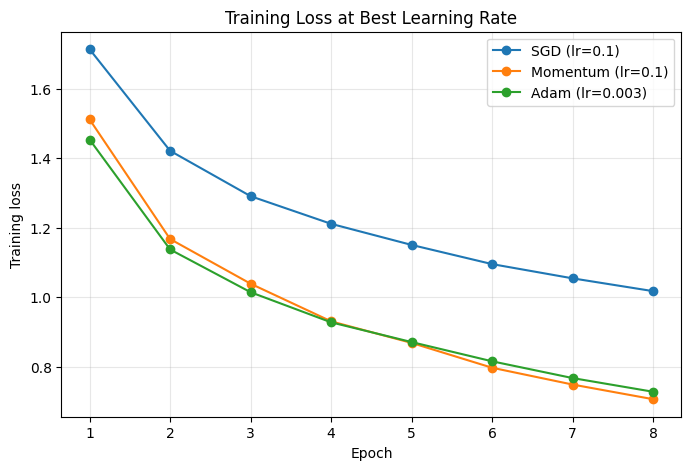

SGD: best LR=0.1, best validation accuracy=59.74%
Momentum: best LR=0.1, best validation accuracy=70.64%
Adam: best LR=0.003, best validation accuracy=69.22%


In [29]:
best_lr = {
    name: max(
        LR_CONFIG[name],
        key=lambda lr: max(experiments[(name, lr)]["val_acc"])
    )
    for name in LR_CONFIG
}

plt.figure(figsize=(8, 5))

for name, lr in best_lr.items():
    losses = experiments[(name, lr)]["train_loss"]
    plt.plot(range(1, len(losses) + 1), losses,
             marker="o", label=f"{name} (lr={lr:g})")

plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Training Loss at Best Learning Rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

for name, lr in best_lr.items():
    result = experiments[(name, lr)]
    print(
        f"{name}: best LR={lr:g}, "
        f"best validation accuracy={max(result['val_acc']):.2f}%"
    )

In [30]:
X_reg, y_reg = X_tr[:5000], y_tr[:5000]

print("Regularization training subset:", tuple(X_reg.shape))
print("Validation set:", tuple(X_va.shape))

Regularization training subset: (5000, 3, 32, 32)
Validation set: (5000, 3, 32, 32)


In [31]:
class RegCNN(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(dropout)
        )
        self.fc = nn.Linear(128, 10)

    def forward(self, x):
        return self.fc(self.features(x))

In [32]:
def flip_crop(x, padding=4):
    # Random horizontal flips
    flip_mask = torch.rand(len(x), device=x.device) < 0.5
    x = x.clone()
    x[flip_mask] = x[flip_mask].flip(-1)

    # Random padded crops
    x = F.pad(x, (padding, padding, padding, padding), value=0)
    offsets_y = torch.randint(0, 2 * padding + 1, (len(x),), device=x.device)
    offsets_x = torch.randint(0, 2 * padding + 1, (len(x),), device=x.device)

    x = torch.stack([
        x[i, :, offsets_y[i]:offsets_y[i]+32,
          offsets_x[i]:offsets_x[i]+32]
        for i in range(len(x))
    ])
    return x


def cutout(x, size=12):
    x = x.clone()
    h, w = x.shape[-2:]
    cy = torch.randint(0, h, (len(x),), device=x.device)
    cx = torch.randint(0, w, (len(x),), device=x.device)

    for i in range(len(x)):
        y1, y2 = max(0, cy[i].item()-size//2), min(h, cy[i].item()+size//2)
        x1, x2 = max(0, cx[i].item()-size//2), min(w, cx[i].item()+size//2)
        x[i, :, y1:y2, x1:x2] = 0

    return x

In [33]:
CONFIGS = {
    "Baseline":       {},
    "Weight decay":   {"weight_decay": 1e-4},
    "Dropout":        {"dropout": 0.3},
    "Flip + crop":    {"flip_crop": True},
    "Cutout":         {"cutout": True},
    "Mixup":          {"mixup": True},
    "All combined":   {
        "weight_decay": 1e-4,
        "dropout": 0.3,
        "flip_crop": True,
        "cutout": True,
        "mixup": True
    }
}

In [34]:
def run_regularization(config, epochs=15):
    torch.manual_seed(42)
    net = RegCNN(dropout=config.get("dropout", 0.0)).to(device)

    optimizer = torch.optim.Adam(
        net.parameters(),
        lr=0.001,
        weight_decay=config.get("weight_decay", 0.0)
    )

    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        net.train()
        loss_sum = correct = total = 0

        for xb, yb in GPULoader(X_reg, y_reg, 128, shuffle=True):
            if config.get("flip_crop"):
                xb = flip_crop(xb)
            if config.get("cutout"):
                xb = cutout(xb)

            optimizer.zero_grad()

            if config.get("mixup"):
                lam = np.random.beta(0.4, 0.4)
                idx = torch.randperm(len(xb), device=device)
                mixed_x = lam * xb + (1 - lam) * xb[idx]
                logits = net(mixed_x)
                loss = (
                    lam * F.cross_entropy(logits, yb)
                    + (1 - lam) * F.cross_entropy(logits, yb[idx])
                )
            else:
                logits = net(xb)
                loss = F.cross_entropy(logits, yb)

            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            total += len(yb)

        hist["train_loss"].append(loss_sum / total)
        hist["train_acc"].append(100 * correct / total)

        net.eval()
        vloss = vcorrect = vtotal = 0

        with torch.no_grad():
            for xb, yb in GPULoader(X_va, y_va, 256, shuffle=False):
                logits = net(xb)
                loss = F.cross_entropy(logits, yb)
                vloss += loss.item() * len(yb)
                vcorrect += (logits.argmax(1) == yb).sum().item()
                vtotal += len(yb)

        hist["val_loss"].append(vloss / vtotal)
        hist["val_acc"].append(100 * vcorrect / vtotal)

        print(
            f"{epoch+1:02d}/{epochs} "
            f"train loss={hist['train_loss'][-1]:.3f} "
            f"train acc={hist['train_acc'][-1]:.1f}% "
            f"val acc={hist['val_acc'][-1]:.1f}%"
        )

    return hist

In [35]:
reg_results = {}

for name, config in CONFIGS.items():
    print(f"\n=== {name} ===")
    reg_results[name] = run_regularization(config, epochs=15)


=== Baseline ===
01/15 train loss=1.921 train acc=31.4% val acc=35.3%
02/15 train loss=1.654 train acc=40.6% val acc=32.5%
03/15 train loss=1.543 train acc=45.2% val acc=41.3%
04/15 train loss=1.449 train acc=48.1% val acc=48.1%
05/15 train loss=1.372 train acc=51.3% val acc=45.0%
06/15 train loss=1.341 train acc=52.1% val acc=41.4%
07/15 train loss=1.291 train acc=54.1% val acc=45.2%
08/15 train loss=1.246 train acc=55.4% val acc=49.0%
09/15 train loss=1.223 train acc=56.7% val acc=47.7%
10/15 train loss=1.190 train acc=58.0% val acc=46.7%
11/15 train loss=1.118 train acc=60.4% val acc=51.0%
12/15 train loss=1.109 train acc=60.8% val acc=52.6%
13/15 train loss=1.080 train acc=61.7% val acc=46.6%
14/15 train loss=1.063 train acc=62.8% val acc=49.8%
15/15 train loss=1.019 train acc=63.7% val acc=49.0%

=== Weight decay ===
01/15 train loss=1.921 train acc=31.4% val acc=35.0%
02/15 train loss=1.654 train acc=40.7% val acc=32.0%
03/15 train loss=1.543 train acc=45.3% val acc=40.7%
04/15 

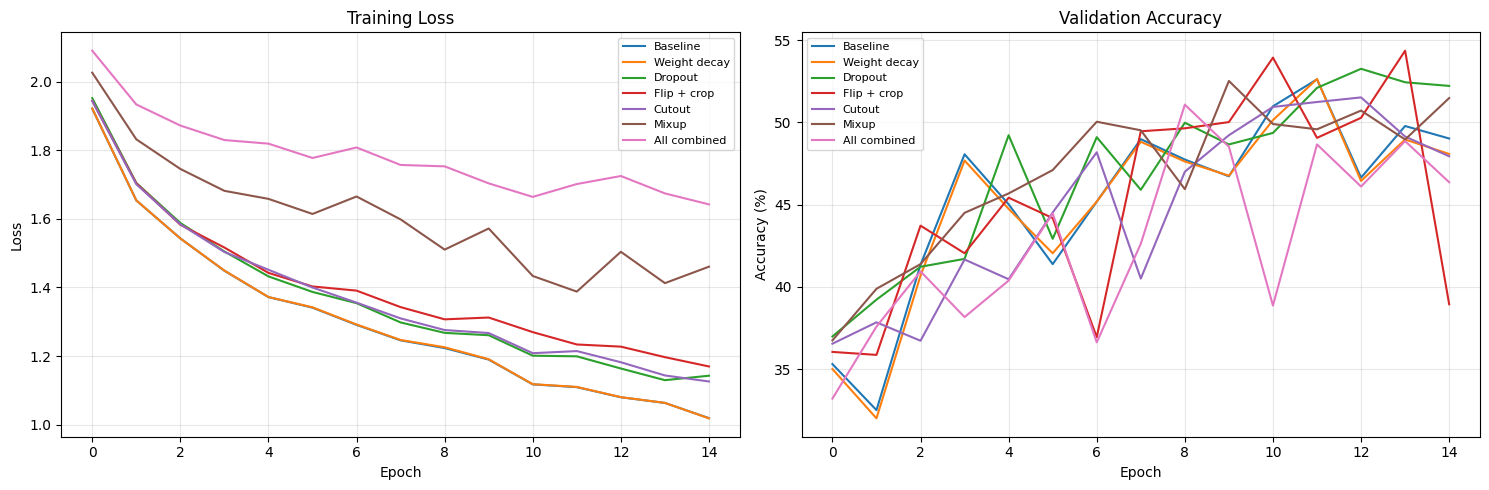

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, hist in reg_results.items():
    axes[0].plot(hist["train_loss"], label=name)
    axes[1].plot(hist["val_acc"], label=name)

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")

for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [37]:
import pandas as pd

rows = []

for name, hist in reg_results.items():
    train_acc = hist["train_acc"][-1]
    val_acc = hist["val_acc"][-1]

    rows.append({
        "Method": name,
        "Train accuracy (%)": round(train_acc, 2),
        "Validation accuracy (%)": round(val_acc, 2),
        "Accuracy gap (percentage points)": round(train_acc - val_acc, 2)
    })

reg_table = pd.DataFrame(rows)
display(reg_table)

,Method,Train accuracy (%),Validation accuracy (%),Accuracy gap (percentage points)
0,Baseline,63.72,49.02,14.70
1,Weight decay,64.00,48.08,15.92
2,Dropout,58.70,52.22,6.48
3,Flip + crop,57.38,38.94,18.44
4,Cutout,59.72,47.94,11.78
5,Mixup,33.24,51.48,-18.24
6,All combined,30.66,46.36,-15.70


In [38]:
class CIFARBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, residual=False):
        super().__init__()
        self.residual = residual

        self.conv1 = nn.Conv2d(
            in_ch, out_ch, 3, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_ch)

        self.conv2 = nn.Conv2d(
            out_ch, out_ch, 3, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_ch)

        if residual and (stride != 1 or in_ch != out_ch):
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        if self.residual:
            out = out + identity

        return F.relu(out)

In [39]:
class CIFARNet(nn.Module):
    def __init__(self, depth=20, residual=False):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6

        self.stem = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU()
        )

        layers = []
        in_ch = 16

        for stage, out_ch in enumerate([16, 32, 64]):
            for block_idx in range(n):
                stride = 2 if stage > 0 and block_idx == 0 else 1
                layers.append(
                    CIFARBlock(in_ch, out_ch, stride, residual=residual)
                )
                in_ch = out_ch

        self.layers = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(64, 10)

        # Kaiming initialization
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(
                    m.weight, mode="fan_out", nonlinearity="relu"
                )
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.stem(x)
        x = self.layers(x)
        x = self.pool(x).flatten(1)
        return self.fc(x)

In [40]:
def train_cifar_net(depth, residual, epochs=10):
    torch.manual_seed(42)
    net = CIFARNet(depth=depth, residual=residual).to(device)
    optimizer = torch.optim.SGD(
        net.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4
    )

    losses = []

    for epoch in range(epochs):
        net.train()
        total_loss, total = 0.0, 0

        for xb, yb in GPULoader(X_tr, y_tr, 128, shuffle=True):
            optimizer.zero_grad()
            logits = net(xb)
            loss = F.cross_entropy(logits, yb)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(yb)
            total += len(yb)

        epoch_loss = total_loss / total
        losses.append(epoch_loss)

        print(
            f"{'ResNet' if residual else 'Plain'}-{depth} "
            f"epoch {epoch+1}/{epochs}: loss={epoch_loss:.4f}"
        )

    return losses

In [41]:
depth_results = {}

for depth in [8, 20, 56]:
    for residual in [False, True]:
        name = f"{'Residual' if residual else 'Plain'}-{depth}"
        print(f"\n=== {name} ===")

        depth_results[name] = train_cifar_net(
            depth=depth, residual=residual, epochs=10
        )


=== Plain-8 ===
Plain-8 epoch 1/10: loss=1.5330
Plain-8 epoch 2/10: loss=1.0770
Plain-8 epoch 3/10: loss=0.9035
Plain-8 epoch 4/10: loss=0.7970
Plain-8 epoch 5/10: loss=0.7138
Plain-8 epoch 6/10: loss=0.6526
Plain-8 epoch 7/10: loss=0.6020
Plain-8 epoch 8/10: loss=0.5662
Plain-8 epoch 9/10: loss=0.5356
Plain-8 epoch 10/10: loss=0.5081

=== Residual-8 ===
ResNet-8 epoch 1/10: loss=1.5286
ResNet-8 epoch 2/10: loss=1.1022
ResNet-8 epoch 3/10: loss=0.9222
ResNet-8 epoch 4/10: loss=0.8164
ResNet-8 epoch 5/10: loss=0.7348
ResNet-8 epoch 6/10: loss=0.6679
ResNet-8 epoch 7/10: loss=0.6167
ResNet-8 epoch 8/10: loss=0.5820
ResNet-8 epoch 9/10: loss=0.5451
ResNet-8 epoch 10/10: loss=0.5164

=== Plain-20 ===
Plain-20 epoch 1/10: loss=1.6744
Plain-20 epoch 2/10: loss=1.1927
Plain-20 epoch 3/10: loss=0.9238
Plain-20 epoch 4/10: loss=0.7686
Plain-20 epoch 5/10: loss=0.6726
Plain-20 epoch 6/10: loss=0.5985
Plain-20 epoch 7/10: loss=0.5428
Plain-20 epoch 8/10: loss=0.5099
Plain-20 epoch 9/10: loss=0.4

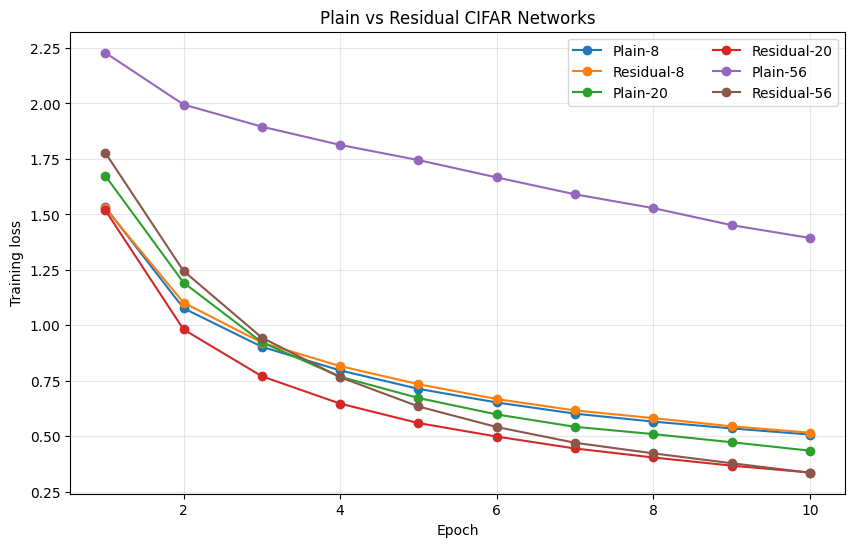

In [42]:
plt.figure(figsize=(10, 6))

for name, losses in depth_results.items():
    plt.plot(range(1, len(losses) + 1), losses, marker="o", label=name)

plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Plain vs Residual CIFAR Networks")
plt.legend(ncol=2)
plt.grid(True, alpha=0.3)
plt.show()